## Isolation Forest – Anomaly Detection

Isolation Forest is an unsupervised machine learning algorithm used to identify anomalies or unusual observations in a dataset.

It works on the principle that anomalies are easier to isolate than normal observations because they are fewer and have different characteristics.

### How It Works
1. Randomly selects a feature.
2. Randomly selects a split value between the minimum and maximum values of that feature.
3. Repeats the process to isolate individual observations.
4. Observations isolated using fewer splits are more likely to be anomalies.

### Key Concepts
- **Isolation Trees:** Random trees used to isolate observations.
- **Contamination:** Expected proportion of anomalies in the dataset.
- **Anomaly Score:** Measures how unusual an observation is.
- **Path Length:** Number of splits required to isolate an observation.
- **Outliers:** Observations that differ significantly from the majority of the data.

### Key Formula

$$
s(x,n)=2^{-\frac{E(h(x))}{c(n)}}
$$

Where:
- \(E(h(x))\) = Average path length for observation \(x\).
- \(c(n)\) = Average path length of unsuccessful searches in a binary search tree.
- \(n\) = Number of observations.

A score closer to 1 indicates a potential anomaly, while a score significantly below 0.5 generally indicates a normal observation.

### Advantages
- Efficient for large datasets.
- Does not require labelled data.
- Handles high-dimensional data.
- Can identify anomalies without defining normal data distributions.

### Limitations
- Sensitive to the contamination parameter.
- May struggle when anomalies are not clearly distinguishable.
- Results can vary due to random sampling.

In [34]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score)

In [35]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.rcParams['font.enable_last_resort'] = False
mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['axes.unicode_minus'] = False

## Credit data

In [36]:
# load data
credit_data = pd.read_csv('../Datasets/creditcard.csv', nrows=40000) 
scaler = StandardScaler().fit_transform(credit_data.loc[:,credit_data.columns!='Class'])
scaled_data = scaler[0:40000]
df = pd.DataFrame(data=scaled_data)
X = credit_data.drop(columns=['Class'])
y = credit_data['Class']

In [37]:
# model
outlier_fraction = len(credit_data[credit_data['Class']==1])/float(len(credit_data[credit_data['Class']==0]))
model =  IsolationForest(n_estimators=100, contamination=outlier_fraction, random_state=42)
model.fit(df)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.0026067776218167233
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [38]:
# evaluation
outlier_fraction = len(credit_data[credit_data['Class']==1])/float(len(credit_data[credit_data['Class']==0]))
model =  IsolationForest(n_estimators=100, contamination=outlier_fraction, random_state=42)
model.fit(df)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.0026067776218167233
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [39]:
# evaluation
scores_prediction = model.decision_function(df)
y_pred = model.predict(df)
y_pred[y_pred == 1] = 0
y_pred[y_pred == -1] = 1
print("Accuracy in finding anomaly:",accuracy_score(y,y_pred))

Accuracy in finding anomaly: 0.997175


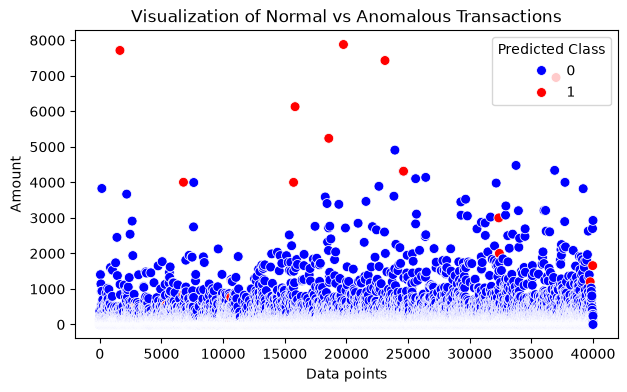

In [40]:
y_feature = credit_data['Amount'] 
credit_data['predicted_class'] = y_pred

plt.figure(figsize=(7, 4))
sns.scatterplot(x=credit_data.index, y=y_feature, hue=credit_data['predicted_class'], palette={0: 'blue', 1: 'red'}, s=50)
plt.title('Visualization of Normal vs Anomalous Transactions')
plt.xlabel('Data points')
plt.ylabel(y_feature.name)
plt.legend(title='Predicted Class', loc='best')
plt.show()

## Synthetic dataset

In [41]:
# generate dataset
X, y = make_blobs(n_samples=500,centers=1,cluster_std=1.0,n_features=2,random_state=42)

outliers = np.random.RandomState(42).uniform(low=-8,high=8,size=(30, 2))

X = np.vstack([X, outliers])
y = np.concatenate([np.zeros(500), np.ones(30)])

isolation_df = pd.DataFrame(X,columns=['Feature_1', 'Feature_2'])

isolation_df['Actual_Label'] = y

print(isolation_df.shape)
isolation_df.head()

(530, 3)


,Feature_1,Feature_2,Actual_Label
0,0.569683,10.133861,0.0
1,-2.686145,8.215989,0.0
2,-2.981129,10.103237,0.0
3,-2.522695,7.956575,0.0
4,-1.922341,11.204742,0.0


In [42]:
isolation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Feature_1     530 non-null    float64
 1   Feature_2     530 non-null    float64
 2   Actual_Label  530 non-null    float64
dtypes: float64(3)
memory usage: 12.6 KB


In [43]:
isolation_df.describe()

,Feature_1,Feature_2,Actual_Label
count,530.000000,530.000000,530.000000
mean,-2.440970,8.559163,0.056604
std,1.478458,2.513781,0.231302
min,-7.670648,-7.256793,0.000000
25%,-3.160735,8.216339,0.000000
50%,-2.490771,8.956051,0.000000
75%,-1.867507,9.682073,0.000000
max,7.513354,12.867018,1.000000


In [44]:
isolation_df.isnull().sum()

Feature_1       0
Feature_2       0
Actual_Label    0
dtype: int64

In [45]:
isolation_df['Actual_Label'].value_counts()

Actual_Label
0.0    500
1.0     30
Name: count, dtype: int64

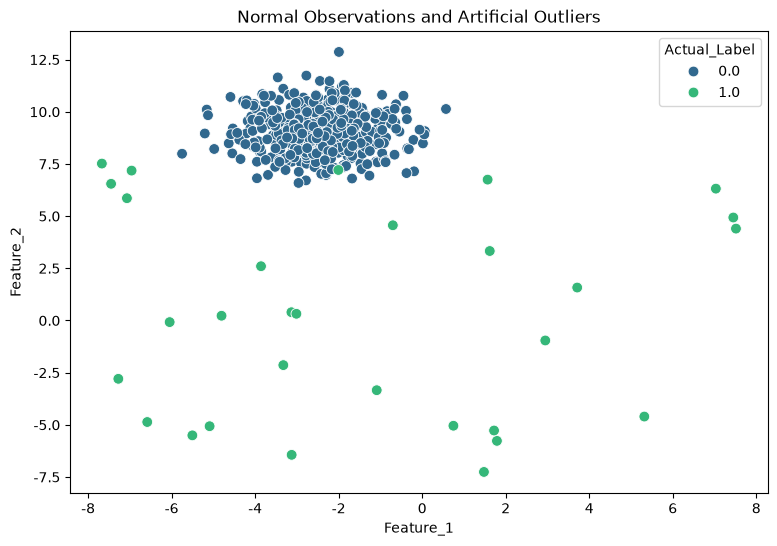

In [46]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=isolation_df,x='Feature_1',y='Feature_2',hue='Actual_Label',palette='viridis',s=60)

plt.title('Normal Observations and Artificial Outliers')
plt.show()

In [47]:
# preprocessing
# separate features and target
X = isolation_df[['Feature_1', 'Feature_2']]
y = isolation_df['Actual_Label']

In [48]:
X.describe()

,Feature_1,Feature_2
count,530.000000,530.000000
mean,-2.440970,8.559163
std,1.478458,2.513781
min,-7.670648,-7.256793
25%,-3.160735,8.216339
50%,-2.490771,8.956051
75%,-1.867507,9.682073
max,7.513354,12.867018


In [49]:
X.isnull().sum()

Feature_1    0
Feature_2    0
dtype: int64

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled,columns=X.columns,index=X.index)

X_scaled.head()

,Feature_1,Feature_2
0,2.038270,0.627018
1,-0.165988,-0.136646
2,-0.365699,0.614824
3,-0.055330,-0.239940
4,0.351122,1.053424


In [51]:
# Modelling
isolation_forest = IsolationForest(n_estimators=100,contamination=30/530,random_state=42)

isolation_forest.fit(X)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05660377358490566
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [52]:
predictions = isolation_forest.predict(X)

isolation_df['Predicted_Label'] = np.where(predictions == -1, 1, 0)
isolation_df['Predicted_Label'].value_counts()

Predicted_Label
0    500
1     30
Name: count, dtype: int64

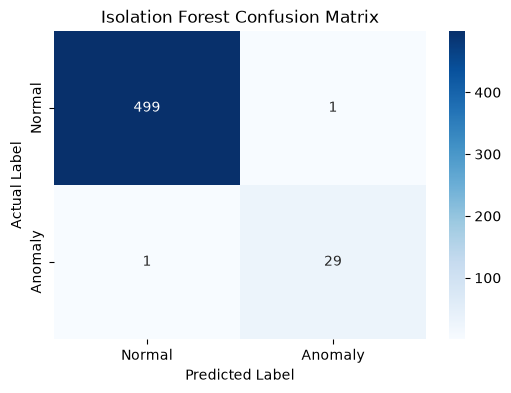

In [53]:
# confusion matrix
cm = confusion_matrix(y, isolation_df['Predicted_Label'])

plt.figure(figsize=(6, 4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Normal', 'Anomaly'],yticklabels=['Normal', 'Anomaly'])

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Isolation Forest Confusion Matrix')
plt.show()

In [54]:
print(classification_report(y,isolation_df['Predicted_Label'],target_names=['Normal', 'Anomaly']))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       500
     Anomaly       0.97      0.97      0.97        30

    accuracy                           1.00       530
   macro avg       0.98      0.98      0.98       530
weighted avg       1.00      1.00      1.00       530



In [55]:
accuracy = accuracy_score(y, isolation_df['Predicted_Label'])
print("Accuracy:", accuracy)

Accuracy: 0.9962264150943396


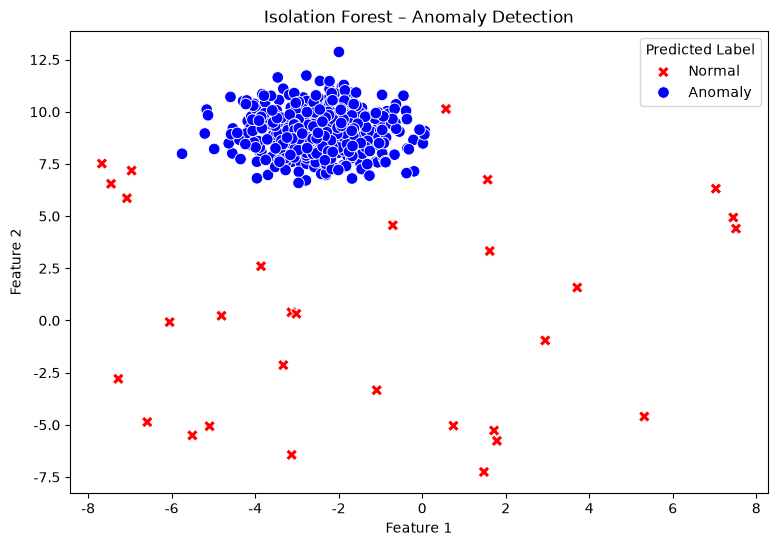

In [56]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=isolation_df,x='Feature_1',y='Feature_2',hue='Predicted_Label',palette={0: 'blue', 1: 'red'},style='Predicted_Label',s=70)

plt.title('Isolation Forest – Anomaly Detection')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(title='Predicted Label', labels=['Normal', 'Anomaly'])
plt.show()

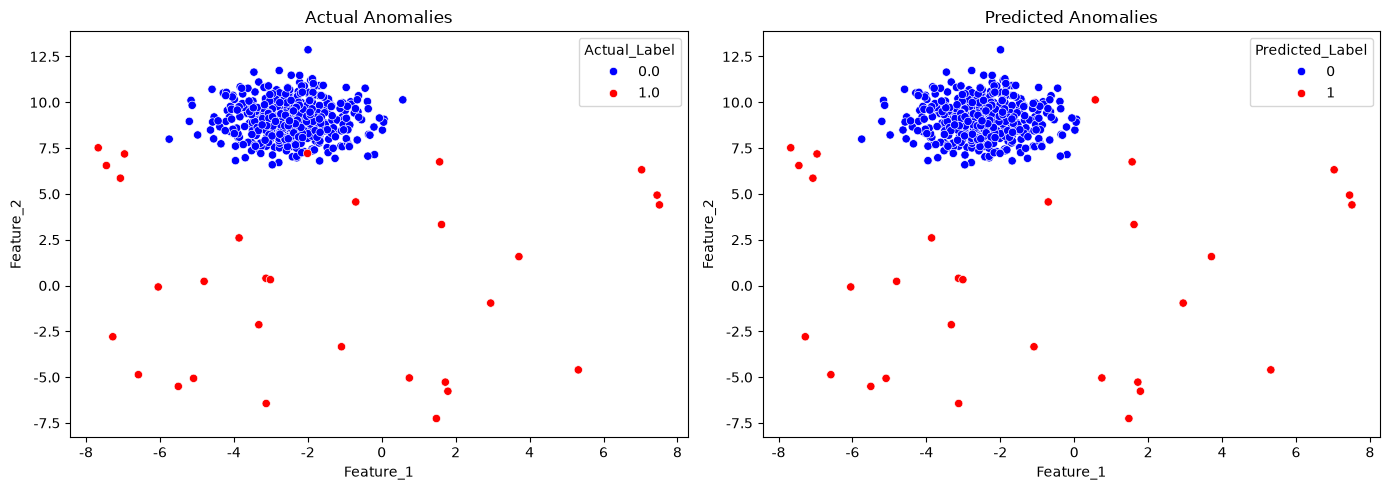

In [57]:
# Actual vs predicted anomalies
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=isolation_df,x='Feature_1',y='Feature_2',hue='Actual_Label',palette={0: 'blue', 1: 'red'},ax=axes[0])
axes[0].set_title('Actual Anomalies')

sns.scatterplot(data=isolation_df,x='Feature_1',y='Feature_2',hue='Predicted_Label',palette={0: 'blue', 1: 'red'},ax=axes[1])
axes[1].set_title('Predicted Anomalies')

plt.tight_layout()
plt.show()

## Conclusion

Isolation Forest was implemented using a synthetic dataset containing 500 normal observations and 30 injected anomalies.

The model achieved an accuracy of **99.62%**, with an anomaly precision, recall, and F1-score of **0.97**.

The results demonstrate that Isolation Forest effectively identified unusual observations by isolating anomalies through random feature selection and splitting.

This experiment demonstrates the usefulness of Isolation Forest for anomaly detection in applications such as fraud detection, network security, and identifying unusual patterns in datasets.